# **[실습 1] Logistic Regression**

## **데이터셋 설명**

여러 스타트업들의 지출 항목별 비용과 순이익에 대한 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| index | 번호 |
| hours_studied | 공부한 시간(H) |
| passed | 시험을 통과했다면1, 아니면 0 |

## **데이터셋 URL**

https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/studies.csv

## **[1-1] Gradient Descent**

### **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

In [29]:
import pandas as pd
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/studies.csv")

**Q2. 각 컬럼의 기본적인 정보를 확인하세요.**

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          20 non-null     int64  
 1   hours_studied  20 non-null     float64
 2   passed         20 non-null     int64  
dtypes: float64(1), int64(2)
memory usage: 612.0 bytes


**Q3. 수치형 컬럼들의 통계 요약을 확인하세요.**

In [31]:
df.describe()

,index,hours_studied,passed
count,20.00000,20.000000,20.000000
mean,9.50000,2.787500,0.500000
std,5.91608,1.507165,0.512989
min,0.00000,0.500000,0.000000
25%,4.75000,1.687500,0.000000
50%,9.50000,2.625000,0.500000
75%,14.25000,4.062500,1.000000
max,19.00000,5.500000,1.000000


### **2. 데이터 시각화하기**

**Q1. hours_studied를 독립변수로, passed를 종속변수로 분리한다.**

In [32]:
X = df['hours_studied'].values
y = df['passed'].values

**Q2. 데이터를 산점도 그래프로 시각화한다.**

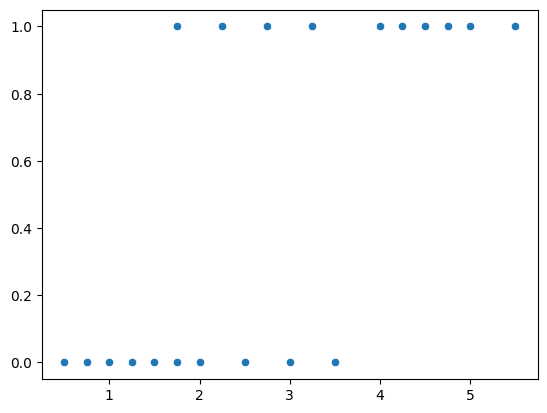

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(x=X, y=y)
plt.show()

### **3. 모델링**

**Q1.LogisticRegression class를 생성한다.**
- 경사하강법을 구현하여 w(coefficient), b(intercept)를 구한다.

각 편미분 값은 다음과 같이 구할 수 있다.
- 𝝏𝒘 = (1/n) * np.sum((y_pred - y) * X)
- 𝛛𝒃 = (1/n) * np.sum(y_pred - y)

predict_proba(X) : X의 데이터가 1이 될 확률을 반환한다. 즉, 0.6이 나온다면, 60% 1(성공/통과) 라는 것이다.

predict(X) : predict_proba의 결과에서 0.5 이상이면 통과(1), 아니면 실패(0)로 변환하여 반환한다.

In [34]:
import numpy as np
class LogisticRegression:
  # hyperparameter: 학습 전 사람이 미리 정해줘야 하는 파라미터들
  #   - lr(learning_rate): 한번에 얼마나 이동시킬까 gradient descent?
  #   - epochs: 학습을 몇 번 수행할까
  def __init__(self, lr = 0.1, epochs = 1000) -> None:
    self.lr = lr
    self.epochs = epochs
    self.w = 0.0
    self.b = 0.0

  def _sigmoid(self, z):
    return 1 / (1 + np.exp(-z))

  def fit(self, X, y):
    # 초기화
    self.b = 0.0
    self.w = 0.0
    n = len(X)

    for _ in range(self.epochs):
      y_pred = self.w * X + self.b # 시그모이드 값에 통과
      y_pred = self._sigmoid(y_pred) # prediction of y

      # 편미분 값 (실제로는 복잡한 수학 수식을 사용)
      dw = (1 / n) * np.sum((y_pred - y) * X) # w가 미치는 영향
      db = (1 / n) * np.sum(y_pred - y)       # b가 미치는 영향

      # w, b 업데이트
      self.w = self.w - (self.lr * dw) # 반대로 가야함, 음수 -> 값 증가 / 양수 -> 값 감소
      self.b = self.b - (self.lr * db)

    return self

  def predict_proba(self, X):
    return self._sigmoid(self.w * X + self.b)

  # return 0 or 1 based on the result
  def predict(self, X):
    # result >= 0.5
    result = self.predict_proba(X)
    print(f"예측 확률 = {result}")
    return result >= 0.5

**Q2. 학습하기**

모델의 instance를 만들고, X, y를 사용해서 학습시킨다.

In [35]:
model = LogisticRegression()
model.fit(X, y)

print(f"w: {model.w} b: {model.b}")

w: 1.328941824772802 b: -3.5559751959432306


**Q3. 예측하기**

predict_proba를 사용해서 예측 결과 (확률)을 y_pred에 저장한다.

In [36]:
y_pred = model.predict(X)
print(y_pred)

예측 확률 = [0.05257514 0.07180626 0.09734901 0.13069838 0.17327926 0.2261242
 0.2261242  0.28944284 0.36219356 0.44185904 0.52463375 0.60607669
 0.6820233  0.74938241 0.85318362 0.89012588 0.91865887 0.94027931
 0.95642563 0.97709447]
[False False False False False False False False False False  True  True
  True  True  True  True  True  True  True  True]


### **4. 결과 시각화하기**

X, y를 활용해서 산점도 그래프를 그린다.
- X, y_pred를 활용해서 선 그래프를 그린다. 선의 색은 빨간색으로 설정한다.

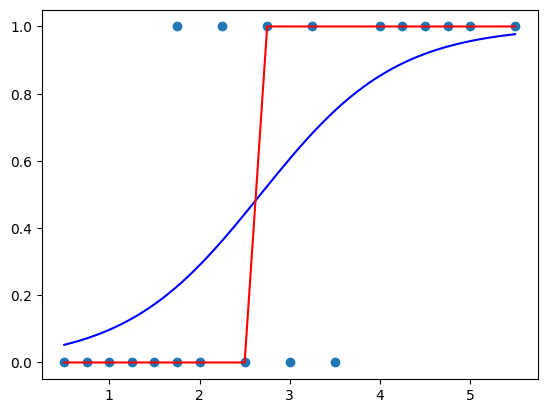

In [37]:
plt.scatter(X, y)

#smooother
x_range = np.linspace(np.min(X), np.max(X), 200)
y_curve = model.predict_proba(x_range)
plt.plot(x_range, y_curve, color='blue')

# angular
plt.plot(X, y_pred, color='red')
plt.show()

## **[1-3] 모델 평가하기**

### **1. Confusion Matrix**

**Q1. 혼동행렬 구하기**

sklearn.metrics의 confusion_matrix를 활용하여 혼동행렬을 구하고 출력해본다.

In [38]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y, y_pred)

array([[8, 2],
       [2, 8]])

**Q2. 혼돈행렬 시각화하기**

seaborn의 heatmap을 활용하여 결과를 시각화한다.

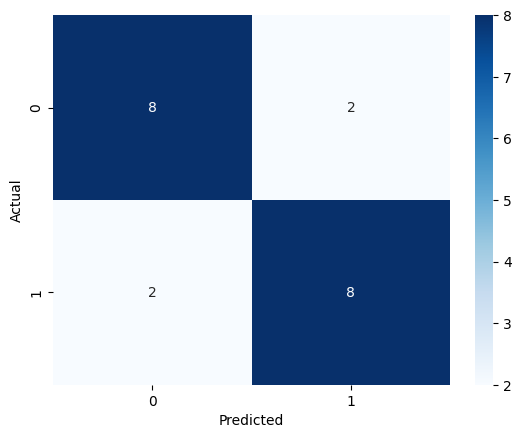

In [42]:
sns.heatmap(confusion_matrix(y, y_pred), annot=True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

### **2. Classification Report**

**Q1. 정확도 출력하기**

In [43]:
from sklearn.metrics import accuracy_score

accuracy_score(y, y_pred)

0.8

**Q2. 분류 리포트 출력하기**

In [45]:
from sklearn.metrics import classification_report

classification_report(y, y_pred)

'              precision    recall  f1-score   support\n\n           0       0.80      0.80      0.80        10\n           1       0.80      0.80      0.80        10\n\n    accuracy                           0.80        20\n   macro avg       0.80      0.80      0.80        20\nweighted avg       0.80      0.80      0.80        20\n'